In [2]:
import numpy as np
import os
from google.colab import files
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import hog
from sklearn import svm
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

print("✅ All Libraries Loaded Successfully")

✅ All Libraries Loaded Successfully


In [3]:
os.makedirs('dataset', exist_ok=True)

print("Please Upload The digits.png Image:")
uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('dataset', filename)
    os.rename(filename, dest)
    print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Dataset Folder:")
print(os.listdir('dataset'))

Please Upload The digits.png Image:


Saving digits.png to digits (1).png
File 'digits (1).png' Moved To 'dataset/digits (1).png'.

Contents Of Dataset Folder:
['digits (1).png']


Loading digits from: dataset/digits (1).png
Digits Shape: (5000, 20, 20)
Labels Shape: (5000,)


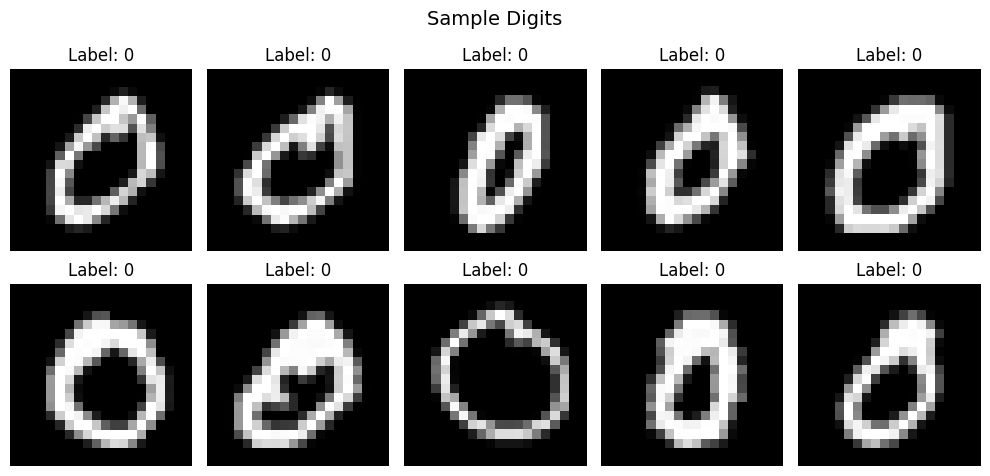

In [5]:
def split2d(img, cell_size, flatten=True):
    h, w = img.shape[:2]
    sx, sy = cell_size
    cells = [np.hsplit(row, w//sx) for row in np.vsplit(img, h//sy)]
    cells = np.array(cells)
    if flatten:
        cells = cells.reshape(-1, sy, sx)
    return cells

def load_digits(file_name):
    img_pil = Image.open(file_name).convert('L')
    digits_img = np.array(img_pil)
    digits = split2d(digits_img, (20, 20))
    labels = np.repeat(np.arange(10), len(digits)//10)
    return digits, labels

possible_paths = ['dataset/digits (1).png', 'dataset/digits.png', 'digits.png']
image_path = None
for path in possible_paths:
    if os.path.exists(path):
        image_path = path
        break

if image_path is None:
    dataset_files = [f for f in os.listdir('dataset') if f.endswith('.png')]
    if dataset_files:
        image_path = os.path.join('dataset', dataset_files[0])

if image_path and os.path.exists(image_path):
    print(f"Loading digits from: {image_path}")
    digits, labels = load_digits(image_path)
    print(f"Digits Shape: {digits.shape}")
    print(f"Labels Shape: {labels.shape}")

    fig, axes = plt.subplots(2, 5, figsize=(10, 5))
    for i, ax in enumerate(axes.flat):
        ax.imshow(digits[i], cmap='gray')
        ax.set_title(f'Label: {labels[i]}')
        ax.axis('off')
    plt.suptitle('Sample Digits', fontsize=14)
    plt.tight_layout()
    plt.show()

In [6]:
rand = np.random.RandomState(10)
shuffle = rand.permutation(len(digits))
digits, labels = digits[shuffle], labels[shuffle]

train_n = int(0.9 * len(digits))
digits_train, digits_test = digits[:train_n], digits[train_n:]
labels_train, labels_test = labels[:train_n], labels[train_n:]

print(f"Training Samples: {len(digits_train)}")
print(f"Testing Samples: {len(digits_test)}")

Training Samples: 4500
Testing Samples: 500


In [7]:
def extract_hog_features(images):
    features = []
    for img in images:
        fd = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True
        )
        features.append(fd)
    return np.array(features)

print("Extracting HOG Features...")
hog_train = extract_hog_features(digits_train)
hog_test = extract_hog_features(digits_test)

print(f"HOG Features Shape (train): {hog_train.shape}")
print(f"HOG Features Shape (test): {hog_test.shape}")

Extracting HOG Features...
HOG Features Shape (train): (4500, 36)
HOG Features Shape (test): (500, 36)


In [8]:
C = 12.5
gamma = 0.50625

model = svm.SVC(kernel='rbf', C=C, gamma=gamma)

print("Training SVM...")
model.fit(hog_train, labels_train)
print("Training Completed!")

Training SVM...
Training Completed!


Percentage Accuracy: 91.00 %


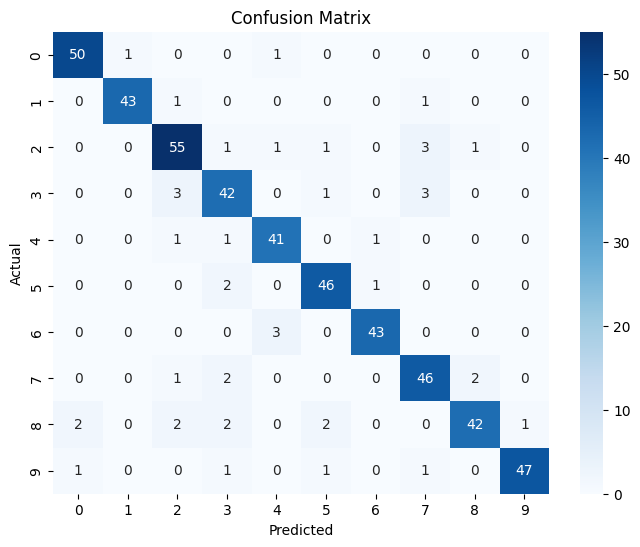

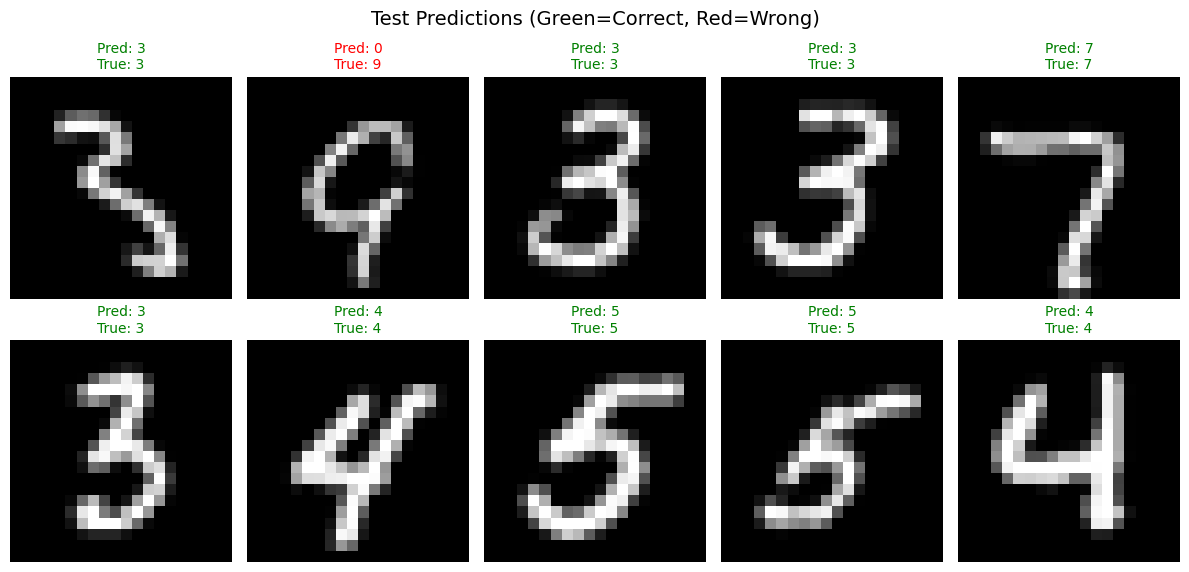

In [9]:
predictions = model.predict(hog_test)

accuracy = accuracy_score(labels_test, predictions)
print(f'Percentage Accuracy: {accuracy * 100:.2f} %')

cm = confusion_matrix(labels_test, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits_test[i], cmap='gray')
    color = 'green' if predictions[i] == labels_test[i] else 'red'
    ax.set_title(f'Pred: {predictions[i]}\nTrue: {labels_test[i]}',
                 color=color, fontsize=10)
    ax.axis('off')
plt.suptitle('Test Predictions (Green=Correct, Red=Wrong)', fontsize=14)
plt.tight_layout()
plt.show()